# AI-Powered E-Commerce Customer Intelligence & Sales Analytics

**Internship Project – IBM SkillsBuild Data Analytics with AI**

**Author:** Deekshitha  
**Project Type:** Data Analytics + Machine Learning + AI-assisted Business Insights

## Project Objective
Analyze online retail transactions to discover sales patterns, understand customer behavior, segment customers using RFM + K-Means, identify anomalous transactions, and build a machine-learning model for monthly sales prediction.

> **Dataset:** UCI Online Retail dataset. It contains 541,909 transaction records from a UK-based non-store online retailer covering 01-Dec-2010 to 09-Dec-2011. The dataset is suitable for clustering and time-series analysis.  
> Source: https://archive.ics.uci.edu/dataset/352/online+retail


In [31]:
# 1. Install/import dependencies
# If needed in a fresh environment, run:
# %pip install pandas numpy matplotlib seaborn scikit-learn ucimlrepo openpyxl

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor, IsolationForest

print("Libraries imported successfully.")


Libraries imported successfully.


In [32]:
!pip install ucimlrepo

# 2. Load the UCI dataset automatically
from ucimlrepo import fetch_ucirepo

online_retail = fetch_ucirepo(id=352)
df = online_retail.data.original.copy()

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [33]:
try:
    from ucimlrepo import fetch_ucirepo
    print("Successfully imported fetch_ucirepo!")
    print("ucimlrepo library installation verified successfully!")
except ImportError as e:
    print("Failed to import ucimlrepo:", e)

Successfully imported fetch_ucirepo!
ucimlrepo library installation verified successfully!


## 3. Dataset Understanding

The main fields are:

- **InvoiceNo** – transaction/invoice identifier; values beginning with `C` indicate cancellations.
- **StockCode** – product identifier.
- **Description** – product name.
- **Quantity** – quantity purchased.
- **InvoiceDate** – transaction date and time.
- **UnitPrice** – price per unit in GBP.
- **CustomerID** – customer identifier.
- **Country** – customer country.

A derived **Revenue** field is calculated as `Quantity × UnitPrice`.


In [34]:
# 4. Initial inspection
print("Rows, columns:", df.shape)
display(df.info())
display(df.describe(include="all").T)


Rows, columns: (541909, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
InvoiceNo,541909,25900,573585,1114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,218.081158,-80995.0,1.0,3.0,10.0,80995.0
InvoiceDate,541909,23260,10/31/2011 14:41,1114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,96.759853,-11062.06,1.25,2.08,4.13,38970.0
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,1713.600303,12346.0,13953.0,15152.0,16791.0,18287.0
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [35]:
# 5. Data quality checks
print("Missing values:")
display(df.isna().sum().sort_values(ascending=False))

print("Duplicate rows:", df.duplicated().sum())


Missing values:


,0
CustomerID,135080
Description,1454
StockCode,0
InvoiceNo,0
Quantity,0
InvoiceDate,0
UnitPrice,0
Country,0


Duplicate rows: 5268


In [36]:
# 6. Data cleaning
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Keep valid sales transactions for revenue/customer analysis
df = df[
    df["CustomerID"].notna() &
    df["Quantity"].gt(0) &
    df["UnitPrice"].gt(0) &
    ~df["InvoiceNo"].astype(str).str.startswith("C")
].copy()

df["CustomerID"] = df["CustomerID"].astype(int)
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

# Additional date features
df["Date"] = df["InvoiceDate"].dt.date
df["YearMonth"] = df["InvoiceDate"].dt.to_period("M").astype(str)
df["Year"] = df["InvoiceDate"].dt.year
df["Month"] = df["InvoiceDate"].dt.month
df["DayOfWeek"] = df["InvoiceDate"].dt.day_name()

print("Cleaned shape:", df.shape)
display(df.head())


Cleaned shape: (392692, 14)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,Date,YearMonth,Year,Month,DayOfWeek
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,2010-12-01,2010-12,2010,12,Wednesday
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12-01,2010-12,2010,12,Wednesday
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,2010-12-01,2010-12,2010,12,Wednesday
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12-01,2010-12,2010,12,Wednesday
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12-01,2010-12,2010,12,Wednesday


## 7. Exploratory Data Analysis (EDA)

The following analysis answers practical business questions:

1. How does revenue change over time?
2. Which products generate the most revenue?
3. Which countries contribute the most revenue?
4. Which days have stronger sales?
5. How many customers and invoices are present?


In [37]:
# 7.1 KPI summary
kpis = pd.Series({
    "Total Revenue (GBP)": df["Revenue"].sum(),
    "Unique Customers": df["CustomerID"].nunique(),
    "Unique Invoices": df["InvoiceNo"].nunique(),
    "Unique Products": df["StockCode"].nunique(),
    "Countries": df["Country"].nunique()
})
display(kpis.to_frame("Value"))


,Value
Total Revenue (GBP),8887208.894
Unique Customers,4338.000
Unique Invoices,18532.000
Unique Products,3665.000
Countries,37.000


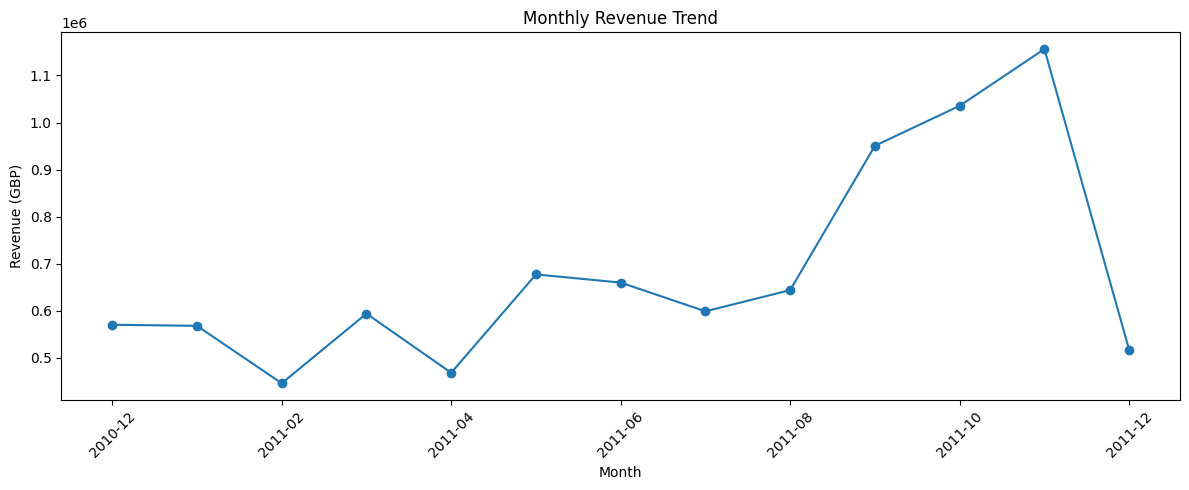

In [38]:
# 7.2 Monthly revenue trend
monthly_sales = df.groupby("YearMonth")["Revenue"].sum()

plt.figure(figsize=(12,5))
monthly_sales.plot(marker="o")
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue (GBP)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


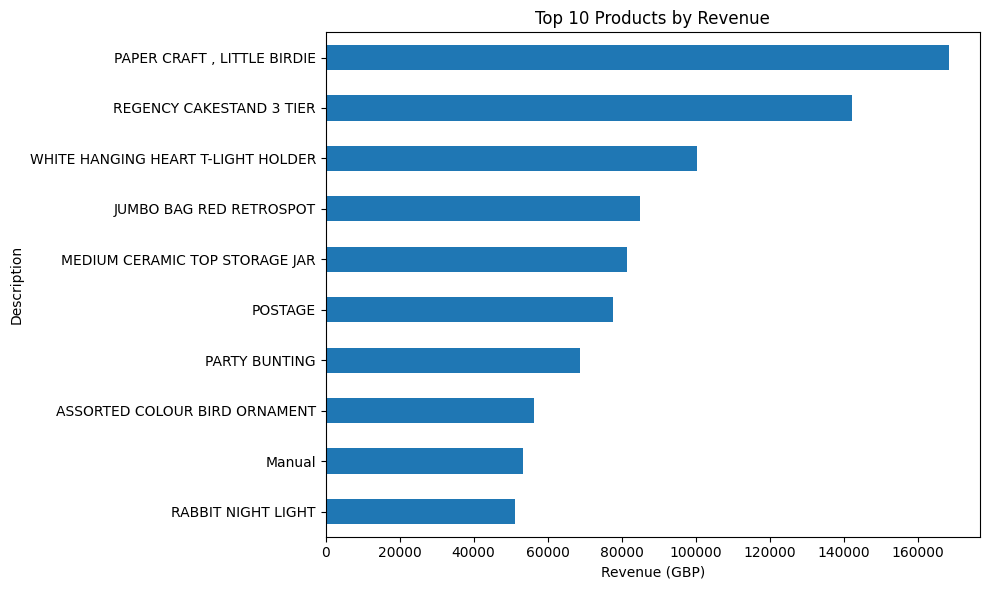

,Revenue
Description,
"PAPER CRAFT , LITTLE BIRDIE",168469.60
REGENCY CAKESTAND 3 TIER,142264.75
WHITE HANGING HEART T-LIGHT HOLDER,100392.10
JUMBO BAG RED RETROSPOT,85040.54
MEDIUM CERAMIC TOP STORAGE JAR,81416.73
POSTAGE,77803.96
PARTY BUNTING,68785.23
ASSORTED COLOUR BIRD ORNAMENT,56413.03
Manual,53419.93


In [39]:
# 7.3 Top products by revenue
top_products = (
    df.groupby("Description")["Revenue"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
      .sort_values()
)

plt.figure(figsize=(10,6))
top_products.plot(kind="barh")
plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (GBP)")
plt.tight_layout()
plt.show()

display(top_products.sort_values(ascending=False).to_frame("Revenue"))


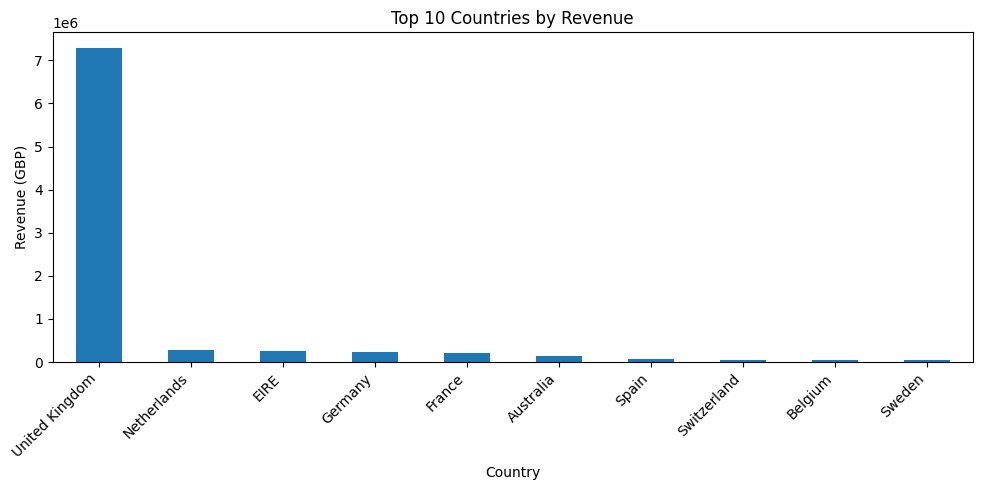

In [40]:
# 7.4 Top countries by revenue
top_countries = (
    df.groupby("Country")["Revenue"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

plt.figure(figsize=(10,5))
top_countries.plot(kind="bar")
plt.title("Top 10 Countries by Revenue")
plt.ylabel("Revenue (GBP)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


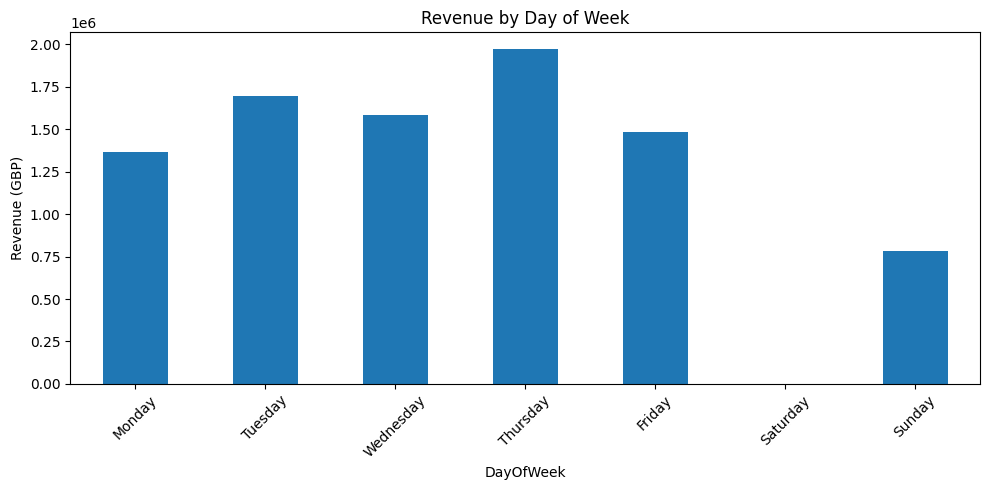

In [41]:
# 7.5 Sales by day of week
day_order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
day_sales = df.groupby("DayOfWeek")["Revenue"].sum().reindex(day_order)

plt.figure(figsize=(10,5))
day_sales.plot(kind="bar")
plt.title("Revenue by Day of Week")
plt.ylabel("Revenue (GBP)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 8. RFM Customer Analysis

RFM is a common customer analytics framework:

- **Recency:** How recently the customer purchased.
- **Frequency:** How often the customer purchased.
- **Monetary:** How much the customer spent.

These three measures provide a compact view of customer value and engagement.


In [42]:
# 8.1 Build RFM table
snapshot_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum")
)

display(rfm.head())
print("Customers in RFM:", len(rfm))


,Recency,Frequency,Monetary
CustomerID,,,
12346,326,1,77183.60
12347,2,7,4310.00
12348,75,4,1797.24
12349,19,1,1757.55
12350,310,1,334.40


Customers in RFM: 4338


In [43]:
# 8.2 RFM scoring using quantiles
# Recency: lower is better, so reverse the score.
rfm["R_Score"] = pd.qcut(rfm["Recency"].rank(method="first"), 5, labels=[5,4,3,2,1]).astype(int)
rfm["F_Score"] = pd.qcut(rfm["Frequency"].rank(method="first"), 5, labels=[1,2,3,4,5]).astype(int)
rfm["M_Score"] = pd.qcut(rfm["Monetary"].rank(method="first"), 5, labels=[1,2,3,4,5]).astype(int)

rfm["RFM_Score"] = rfm["R_Score"] + rfm["F_Score"] + rfm["M_Score"]

def rfm_segment(row):
    if row["RFM_Score"] >= 13:
        return "Champions"
    elif row["RFM_Score"] >= 10:
        return "Loyal Customers"
    elif row["RFM_Score"] >= 7:
        return "Potential Loyalists"
    elif row["RFM_Score"] >= 5:
        return "At Risk"
    else:
        return "Needs Attention"

rfm["Segment"] = rfm.apply(rfm_segment, axis=1)

display(rfm.sort_values("RFM_Score", ascending=False).head(10))
display(rfm["Segment"].value_counts())


,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
CustomerID,,,,,,,,
18245,7,7,2567.06,5,5,5,15,Champions
18241,10,17,2073.09,5,5,5,15,Champions
18230,9,7,2810.20,5,5,5,15,Champions
18229,12,20,7276.90,5,5,5,15,Champions
18225,3,12,5504.96,5,5,5,15,Champions
18223,5,14,6484.54,5,5,5,15,Champions
18219,3,10,2069.77,5,5,5,15,Champions
18210,2,6,2621.38,5,5,5,15,Champions
18198,4,17,5425.56,5,5,5,15,Champions


,count
Segment,
Potential Loyalists,1085
Loyal Customers,1012
Champions,929
At Risk,765
Needs Attention,547


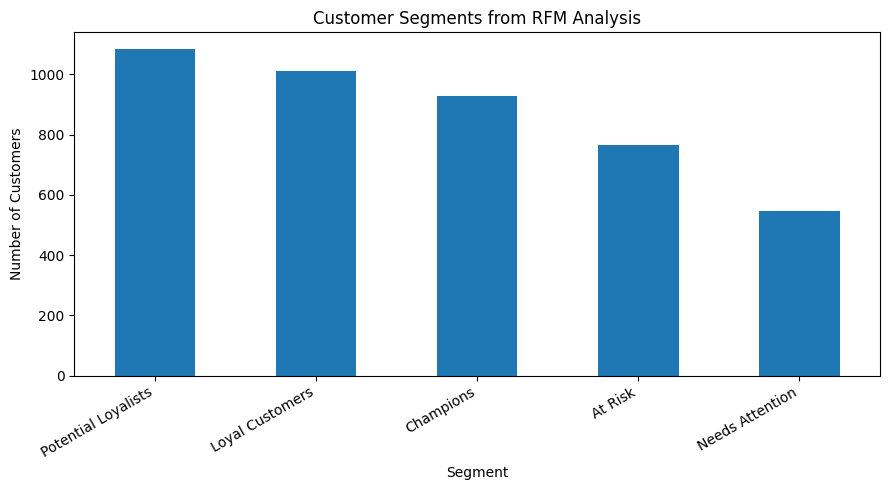

In [44]:
# 8.3 RFM segment visualization
segment_counts = rfm["Segment"].value_counts()

plt.figure(figsize=(9,5))
segment_counts.plot(kind="bar")
plt.title("Customer Segments from RFM Analysis")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


## 9. Customer Segmentation with K-Means

K-Means groups customers with similar behavior. We use standardized RFM variables so that differences in scale do not dominate the clustering process.


In [45]:
# 9.1 Prepare RFM features
rfm_features = rfm[["Recency", "Frequency", "Monetary"]].copy()

# Log transform reduces the effect of highly skewed monetary/frequency values.
rfm_log = np.log1p(rfm_features)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(rfm_log)

# Compare several k values using silhouette score
scores = {}
for k in range(2, 8):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    scores[k] = silhouette_score(X_scaled, labels)

display(pd.Series(scores, name="Silhouette Score"))

best_k = max(scores, key=scores.get)
print("Best k based on silhouette score:", best_k)


,Silhouette Score
2,0.432827
3,0.336517
4,0.337517
5,0.316200
6,0.312409
7,0.309186


Best k based on silhouette score: 2


In [46]:
# 9.2 Final K-Means model
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
rfm["Cluster"] = kmeans.fit_predict(X_scaled)

cluster_summary = rfm.groupby("Cluster")[["Recency","Frequency","Monetary"]].mean().round(2)
cluster_summary["Customers"] = rfm.groupby("Cluster").size()

display(cluster_summary)


,Recency,Frequency,Monetary,Customers
Cluster,,,,
0,134.09,1.67,495.59,2672
1,25.89,8.44,4539.60,1666


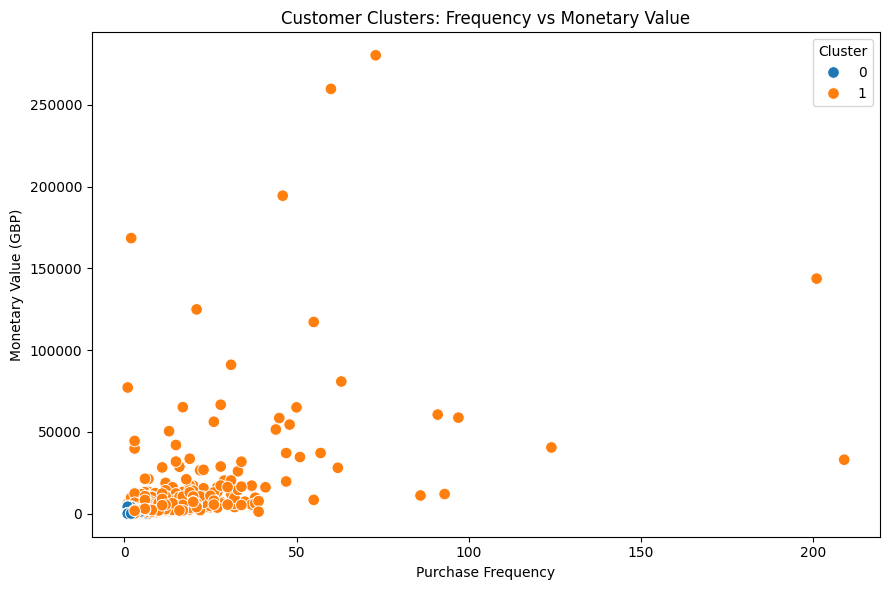

In [47]:
# 9.3 Cluster visualization
plt.figure(figsize=(9,6))
sns.scatterplot(
    data=rfm,
    x="Frequency",
    y="Monetary",
    hue="Cluster",
    palette="tab10",
    s=70
)
plt.title("Customer Clusters: Frequency vs Monetary Value")
plt.xlabel("Purchase Frequency")
plt.ylabel("Monetary Value (GBP)")
plt.tight_layout()
plt.show()


## 10. Anomaly Detection

Anomaly detection can highlight unusually large or unusual customer-level monetary behavior. This is an analytical signal, not a claim of fraud.


In [48]:
# 10.1 Isolation Forest on customer RFM features
iso = IsolationForest(
    contamination=0.02,
    random_state=42
)

rfm["Anomaly"] = iso.fit_predict(X_scaled)
rfm["Anomaly_Label"] = rfm["Anomaly"].map({1: "Normal", -1: "Anomalous"})

print(rfm["Anomaly_Label"].value_counts())
display(
    rfm[rfm["Anomaly_Label"] == "Anomalous"]
    .sort_values("Monetary", ascending=False)
    .head(15)
)


Anomaly_Label
Normal       4251
Anomalous      87
Name: count, dtype: int64


,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment,Cluster,Anomaly,Anomaly_Label
CustomerID,,,,,,,,,,,
14646,2,73,280206.02,5,5,5,15,Champions,1,-1,Anomalous
18102,1,60,259657.30,5,5,5,15,Champions,1,-1,Anomalous
17450,8,46,194390.79,5,5,5,15,Champions,1,-1,Anomalous
16446,1,2,168472.50,5,3,5,13,Champions,1,-1,Anomalous
14911,1,201,143711.17,5,5,5,15,Champions,1,-1,Anomalous
12415,24,21,124914.53,4,5,5,14,Champions,1,-1,Anomalous
14156,10,55,117210.08,5,5,5,15,Champions,1,-1,Anomalous
17511,3,31,91062.38,5,5,5,15,Champions,1,-1,Anomalous
16029,39,63,80850.84,3,5,5,13,Champions,1,-1,Anomalous


## 11. Monthly Sales Prediction

A supervised machine-learning model is used to predict monthly revenue from calendar/time-series features and lagged revenue.

Because the dataset is chronological, the split is time-aware: earlier months are used for training and later months for testing.


In [49]:
# 11.1 Build monthly modeling table
sales = monthly_sales.rename("Revenue").to_frame()
sales.index = pd.to_datetime(sales.index)

sales_model = sales.copy()
sales_model["Year"] = sales_model.index.year
sales_model["Month"] = sales_model.index.month
sales_model["MonthNum"] = np.arange(len(sales_model))
sales_model["Lag1"] = sales_model["Revenue"].shift(1)
sales_model["Lag2"] = sales_model["Revenue"].shift(2)
sales_model["Rolling3"] = sales_model["Revenue"].shift(1).rolling(3).mean()

sales_model = sales_model.dropna()

features = ["Year", "Month", "MonthNum", "Lag1", "Lag2", "Rolling3"]
X = sales_model[features]
y = sales_model["Revenue"]

split = int(len(sales_model) * 0.8)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_train, y_test = y.iloc[:split], y.iloc[split:]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


Training rows: 8
Testing rows: 2


In [50]:
# 11.2 Train Random Forest regression model
rf_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    max_depth=8,
    min_samples_leaf=1
)

rf_model.fit(X_train, y_train)
pred = rf_model.predict(X_test)

mae = mean_absolute_error(y_test, pred)
rmse = np.sqrt(mean_squared_error(y_test, pred))
r2 = r2_score(y_test, pred)

metrics = pd.Series({
    "MAE": mae,
    "RMSE": rmse,
    "R2": r2
})
display(metrics.to_frame("Value"))


,Value
MAE,319507.585000
RMSE,341021.720743
R2,-0.139205


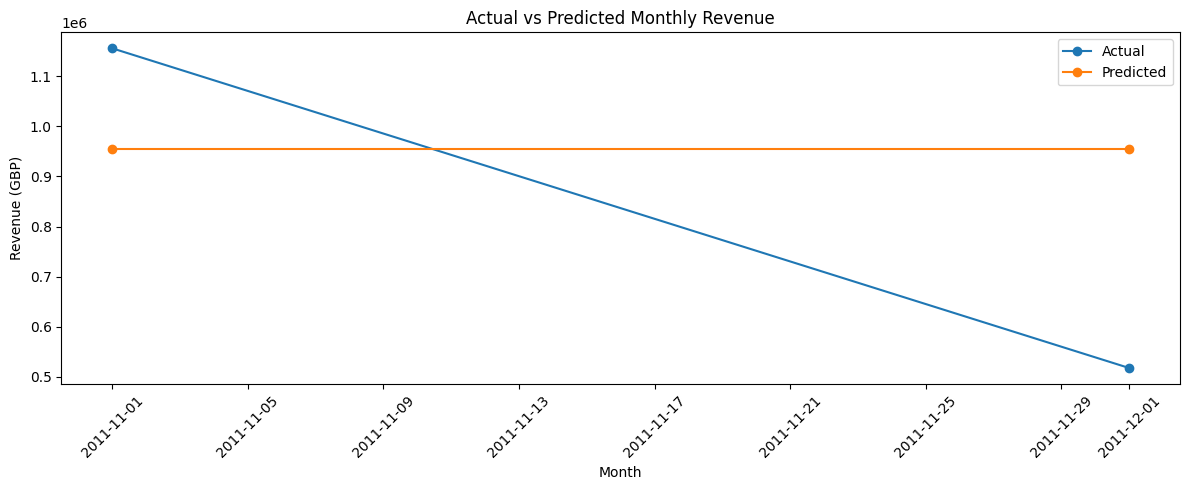

,Actual,Predicted
YearMonth,,
2011-11-01,1156205.61,955906.737543
2011-12-01,517190.44,955906.737543


In [51]:
# 11.3 Actual vs predicted monthly revenue
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": pred
}, index=y_test.index)

plt.figure(figsize=(12,5))
plt.plot(comparison.index, comparison["Actual"], marker="o", label="Actual")
plt.plot(comparison.index, comparison["Predicted"], marker="o", label="Predicted")
plt.title("Actual vs Predicted Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (GBP)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(comparison)


In [52]:
# 11.4 Forecast the next month
last_date = sales_model.index.max()
next_date = last_date + pd.offsets.MonthBegin(1)

next_features = pd.DataFrame([{
    "Year": next_date.year,
    "Month": next_date.month,
    "MonthNum": len(sales_model),
    "Lag1": sales_model["Revenue"].iloc[-1],
    "Lag2": sales_model["Revenue"].iloc[-2],
    "Rolling3": sales_model["Revenue"].iloc[-3:].mean()
}])

next_prediction = rf_model.predict(next_features[features])[0]

print(f"Next-month forecast ({next_date.strftime('%Y-%m')}): £{next_prediction:,.2f}")


Next-month forecast (2012-01): £772,944.49


## 12. Business Insights Generator

The following section converts model outputs into concise, data-driven recommendations.


In [53]:
# 12.1 Automatically generate project insights
best_product = df.groupby("Description")["Revenue"].sum().idxmax()
best_country = df.groupby("Country")["Revenue"].sum().idxmax()
best_day = day_sales.idxmax()
largest_segment = rfm["Segment"].value_counts().idxmax()

print("AI-assisted Business Insights")
print("-" * 60)
print(f"• Highest-revenue product: {best_product}")
print(f"• Highest-revenue country: {best_country}")
print(f"• Strongest revenue day: {best_day}")
print(f"• Largest RFM segment: {largest_segment}")
print(f"• Detected customer-level anomalies: {(rfm['Anomaly_Label'] == 'Anomalous').sum()}")
print(f"• Next-month revenue forecast: £{next_prediction:,.2f}")

print("\nRecommended actions:")
print("1. Focus retention campaigns on high-value/loyal customers.")
print("2. Create targeted re-engagement campaigns for at-risk customers.")
print("3. Use top-performing products for bundles and cross-selling.")
print("4. Investigate anomalous customer patterns before making business decisions.")
print("5. Use the monthly forecast as a planning signal rather than a guaranteed outcome.")


AI-assisted Business Insights
------------------------------------------------------------
• Highest-revenue product: PAPER CRAFT , LITTLE BIRDIE
• Highest-revenue country: United Kingdom
• Strongest revenue day: Thursday
• Largest RFM segment: Potential Loyalists
• Detected customer-level anomalies: 87
• Next-month revenue forecast: £772,944.49

Recommended actions:
1. Focus retention campaigns on high-value/loyal customers.
2. Create targeted re-engagement campaigns for at-risk customers.
3. Use top-performing products for bundles and cross-selling.
4. Investigate anomalous customer patterns before making business decisions.
5. Use the monthly forecast as a planning signal rather than a guaranteed outcome.


## 13. Conclusion

This project combines descriptive analytics, customer analytics, unsupervised learning, anomaly detection and supervised machine learning.

The workflow transforms raw transaction data into:
- measurable business KPIs,
- customer segments,
- anomaly signals,
- sales forecasts,
- and actionable business recommendations.

### Future Scope
- Build an interactive Streamlit dashboard.
- Add product recommendation using association-rule mining.
- Add customer lifetime value modeling.
- Experiment with gradient boosting and time-series models.
- Deploy the pipeline as a web application/API.


## 14. References

1. Chen, D. (2015). **Online Retail**. UCI Machine Learning Repository. DOI: 10.24432/C5BW33.
2. UCI Machine Learning Repository: https://archive.ics.uci.edu/dataset/352/online+retail
3. scikit-learn documentation: https://scikit-learn.org/
4. pandas documentation: https://pandas.pydata.org/
5. NumPy documentation: https://numpy.org/
